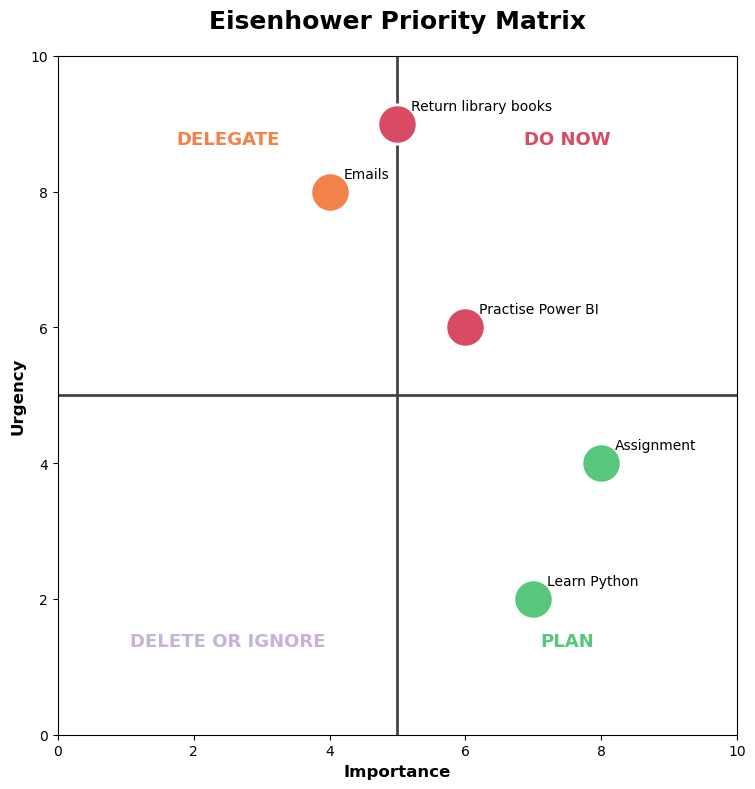

Task,Importance,Urgency,Category,Status
Assignment,8,4,Schedule,
Learn Python,7,2,Schedule,
Emails,4,8,Delegate,
Practise Power BI,6,6,Do Now,
Return library books,5,9,Do Now,


In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# ======================================
# READ EXCEL
# ======================================

df = pd.read_excel("./Tasks_Priority.xlsx")

# ======================================
# EISENHOWER CATEGORIES
# ======================================

def eisenhower_category(importance, urgency):

    if importance >= 5 and urgency >= 5:
        return "Do Now", "#D84B63"

    elif importance >= 5 and urgency < 5:
        return "Schedule", "#58C77B"

    elif importance < 5 and urgency >= 5:
        return "Delegate", "#F2814A"

    else:
        return "Eliminate", "#C5B3D9"


df[["Category", "Color"]] = df.apply(
    lambda row: pd.Series(
        eisenhower_category(
            row["Importance"],
            row["Urgency"]
        )
    ),
    axis=1
)

# ======================================
# CHART
# ======================================

plt.rcParams["font.family"] = "DejaVu Sans"

fig, ax = plt.subplots(figsize=(8, 8))

ax.set_aspect("equal")

# Plot tasks
for _, row in df.iterrows():

    ax.scatter(
        row["Importance"],
        row["Urgency"],
        s=800,
        color=row["Color"],
        edgecolor="white",
        linewidth=2,
        zorder=3
    )

    ax.annotate(
        row["Task"],
        (row["Importance"], row["Urgency"]),
        xytext=(10, 10),
        textcoords="offset points",
        fontsize=10
    )

# Matrix lines
ax.axvline(
    x=5,
    color="#444444",
    linewidth=2
)

ax.axhline(
    y=5,
    color="#444444",
    linewidth=2
)

# Quadrant labels
ax.text(
    7.5, 8.7,
    "DO NOW",
    ha="center",
    fontsize=13,
    fontweight="bold",
    color="#D84B63"
)

ax.text(
    7.5, 1.3,
    "PLAN",
    ha="center",
    fontsize=13,
    fontweight="bold",
    color="#58C77B"
)

ax.text(
    2.5, 8.7,
    "DELEGATE",
    ha="center",
    fontsize=13,
    fontweight="bold",
    color="#F2814A"
)

ax.text(
    2.5, 1.3,
    "DELETE OR IGNORE",
    ha="center",
    fontsize=13,
    fontweight="bold",
    color="#C5B3D9"
)

# Titles and axes
ax.set_title(
    "Eisenhower Priority Matrix",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Importance",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Urgency",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)

ax.grid(False)

plt.tight_layout()

# Save chart
plt.savefig(
    "eisenhower_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ======================================
# TABLE WITH COLOURED BUBBLES
# ======================================

print()
print()

df["Status"] = df["Color"].apply(
    lambda c: (
        f'<span style="'
        f'display:inline-block;'
        f'width:20px;'
        f'height:20px;'
        f'border-radius:50%;'
        f'background:{c};'
        f'border:1px solid #999;'
        f'"></span>'
    )
)

html = """
<style>
table {
    border-collapse: collapse;
    font-family: Arial, sans-serif;
    font-size: 12pt;
}

th, td {
    text-align: left !important;
    padding: 10px 14px;
    font-size: 12pt;
    vertical-align: middle;
}

th {
    font-weight: bold;
    border-bottom: 1px solid #cccccc;
}

tbody tr:nth-child(even) {
    background-color: #f5f5f5;
}

th:first-child,
td:first-child {
    min-width: 220px;
}

th:last-child,
td:last-child {
    text-align: center !important;
}
</style>
"""

html += df[
    [
        "Task",
        "Importance",
        "Urgency",
        "Category",
        "Status"
    ]
].to_html(
    escape=False,
    index=False
)

display(HTML(html))
